# Milestone 3: Final Held-Out Test Evaluation & Operational Triage Metrics

This notebook evaluates the serialized unsupervised Gaussian Mixture Model (`best_gmm.joblib`, $k=10$, 29 leak-free features) on the chronological test partition (`test.csv`).

**Evaluation Suite:**
1. **Global Ranking Metrics:** Area Under the Receiver Operating Characteristic Curve (ROC-AUC) and Area Under the Precision-Recall Curve (PR-AUC).
2. **FPR-Constrained Operating Points:** Fraud recall and precision under strict False Positive Rate budgets ($\text{FPR} \le 0.1\%, 0.5\%, 1.0\%$).
3. **Capacity-Constrained Alert Triage:** $\text{Precision@}K$ and $\text{Recall@}K$ for daily analyst review queues ($K \in \{50, 100, 200, 500\}$).
4. **1st-Percentile Training Threshold Evaluation:** Confusion matrix and classification metrics at the unsupervised training log-likelihood cutoff.

In [7]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    auc,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

# Resolve paths cleanly without mutating global working directory
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

# Load serialized scaler and GMM
scaler = joblib.load(MODELS_DIR / "scaler.joblib")
best_gmm = joblib.load(MODELS_DIR / "best_gmm.joblib")

# Load train (for 1st percentile threshold reference) and test splits
train_df = pd.read_csv(PROCESSED_DIR / "train_legit.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

assert "Time" not in test_df.columns, "Leakage check failed: Time column present in test.csv!"

X_train_scaled = scaler.transform(train_df)
train_log_likelihoods = best_gmm.score_samples(X_train_scaled)
threshold_1pct_ll = float(np.percentile(train_log_likelihoods, 1))

X_test = test_df.drop(columns=["Class"])
y_test = test_df["Class"].to_numpy()
X_test_scaled = scaler.transform(X_test)

# Compute log-likelihoods and convert to anomaly scores (-log_likelihood)
test_log_likelihoods = best_gmm.score_samples(X_test_scaled)
anomaly_scores = -test_log_likelihoods

# Global metrics
roc_auc = roc_auc_score(y_test, anomaly_scores)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, anomaly_scores)
pr_auc = auc(recall_curve, precision_curve)
baseline_pr = float(y_test.mean())

print("=" * 60)
print("FINAL HELD-OUT TEST SET GLOBAL METRICS (29 FEATURES)")
print("=" * 60)
print(f"GMM Components (k)            : {best_gmm.n_components}")
print(f"Test Set Size                 : {len(y_test):,} ({int(y_test.sum())} fraud, {int((y_test == 0).sum()):,} legit)")
print(f"Random Baseline PR-AUC        : {baseline_pr:.4f} ({baseline_pr * 100:.3f}%)")
print(f"Test ROC-AUC                  : {roc_auc:.4f}")
print(f"Test PR-AUC                   : {pr_auc:.4f} ({pr_auc / baseline_pr:.1f}x lift over random)")
print(f"1st-Pct Train LL Threshold    : {threshold_1pct_ll:.4f}")
print("=" * 60)

FINAL HELD-OUT TEST SET GLOBAL METRICS (29 FEATURES)
GMM Components (k)            : 10
Test Set Size                 : 56,962 (75 fraud, 56,887 legit)
Random Baseline PR-AUC        : 0.0013 (0.132%)
Test ROC-AUC                  : 0.9106
Test PR-AUC                   : 0.4736 (359.7x lift over random)
1st-Pct Train LL Threshold    : -51.9057


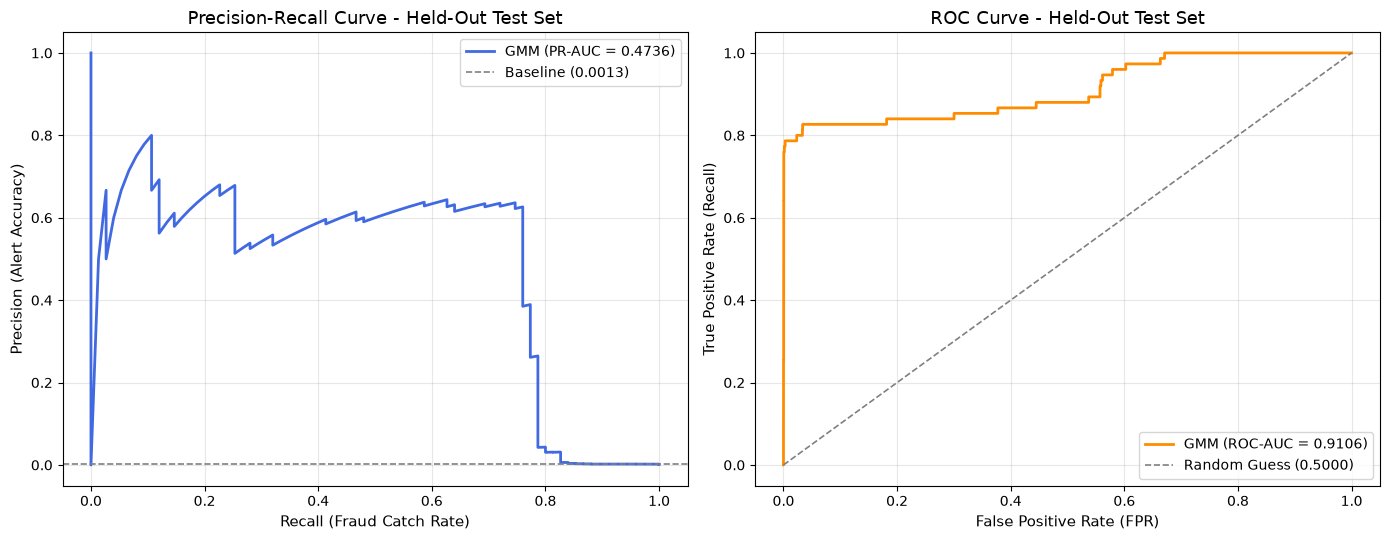

In [8]:
fpr_curve, tpr_curve, _ = roc_curve(y_test, anomaly_scores)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Precision-Recall Curve
axes[0].plot(recall_curve, precision_curve, color="royalblue", lw=2, label=f"GMM (PR-AUC = {pr_auc:.4f})")
axes[0].axhline(baseline_pr, color="gray", linestyle="--", lw=1.2, label=f"Baseline ({baseline_pr:.4f})")
axes[0].set_xlabel("Recall (Fraud Catch Rate)", fontsize=11)
axes[0].set_ylabel("Precision (Alert Accuracy)", fontsize=11)
axes[0].set_title("Precision-Recall Curve - Held-Out Test Set", fontsize=13)
axes[0].legend(loc="upper right", fontsize=10)
axes[0].grid(True, alpha=0.3)

# 2. ROC Curve
axes[1].plot(fpr_curve, tpr_curve, color="darkorange", lw=2, label=f"GMM (ROC-AUC = {roc_auc:.4f})")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", lw=1.2, label="Random Guess (0.5000)")
axes[1].set_xlabel("False Positive Rate (FPR)", fontsize=11)
axes[1].set_ylabel("True Positive Rate (Recall)", fontsize=11)
axes[1].set_title("ROC Curve - Held-Out Test Set", fontsize=13)
axes[1].legend(loc="lower right", fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
# --- 1. Recall & Precision at Fixed FPR Budgets ---
fpr_budgets = [0.001, 0.005, 0.010]  # 0.1%, 0.5%, 1.0%
legit_scores = anomaly_scores[y_test == 0]
n_total_fraud = int(y_test.sum())
n_total_legit = int((y_test == 0).sum())

fpr_rows = []
for budget in fpr_budgets:
    # Score cutoff derived on legitimate distribution for target FPR
    score_cutoff = float(np.quantile(legit_scores, 1.0 - budget))
    preds = (anomaly_scores >= score_cutoff).astype(int)
    tp = int(((preds == 1) & (y_test == 1)).sum())
    fp = int(((preds == 1) & (y_test == 0)).sum())
    actual_fpr = fp / n_total_legit
    recall_val = tp / n_total_fraud
    precision_val = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    fpr_rows.append({
        "FPR Budget": f"<= {budget * 100:.1f}%",
        "Actual Test FPR": f"{actual_fpr * 100:.2f}%",
        "Anomaly Cutoff": f"{score_cutoff:.2f}",
        "Fraud Caught (TP)": f"{tp} / {n_total_fraud}",
        "False Alarms (FP)": f"{fp:,}",
        "Recall": f"{recall_val * 100:.2f}%",
        "Precision": f"{precision_val * 100:.2f}%",
    })

fpr_df = pd.DataFrame(fpr_rows)
print("\n=== TABLE 1: PERFORMANCE AT FIXED FALSE POSITIVE RATE (FPR) BUDGETS ===")
print(fpr_df.to_string(index=False))

# --- 2. Precision@K and Recall@K for Analyst Alert Queues ---
k_budgets = [50, 100, 200, 500]
sorted_indices = np.argsort(anomaly_scores)[::-1]  # Highest anomaly score first

topk_rows = []
for k in k_budgets:
    top_k_labels = y_test[sorted_indices[:k]]
    tp_k = int(top_k_labels.sum())
    prec_k = tp_k / k
    rec_k = tp_k / n_total_fraud
    lift_k = prec_k / baseline_pr
    topk_rows.append({
        "Alert Queue (K)": f"Top-{k}",
        "True Frauds (TP)": f"{tp_k} / {n_total_fraud}",
        "Precision@K": f"{prec_k * 100:.2f}%",
        "Recall@K": f"{rec_k * 100:.2f}%",
        "Lift vs Random": f"{lift_k:.1f}x",
    })

topk_df = pd.DataFrame(topk_rows)
print("\n=== TABLE 2: ANALYST ALERT QUEUE TRIAGE (PRECISION@K & RECALL@K) ===")
print(topk_df.to_string(index=False))

# --- 3. Confusion Matrix at 1st Percentile Training Threshold ---
y_test_pred_1pct = (test_log_likelihoods < threshold_1pct_ll).astype(int)
cm = confusion_matrix(y_test, y_test_pred_1pct)
tn, fp, fn, tp = cm.ravel()

print(f"\n=== TABLE 3: TEST EVALUATION AT 1ST PERCENTILE TRAIN THRESHOLD (LL < {threshold_1pct_ll:.4f}) ===")
print(f"Confusion Matrix:\n{cm}")
print(f"  True Negatives  (Legit Correctly Passed) : {tn:,}")
print(f"  False Positives (Legit Flagged as Alert) : {fp:,} (FPR = {fp / n_total_legit * 100:.2f}%)")
print(f"  False Negatives (Fraud Missed)           : {fn}")
print(f"  True Positives  (Fraud Caught)           : {tp} / {n_total_fraud} (Recall = {tp / n_total_fraud * 100:.2f}%)")
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_1pct, target_names=["Legitimate (0)", "Fraud (1)"], digits=4))


=== TABLE 1: PERFORMANCE AT FIXED FALSE POSITIVE RATE (FPR) BUDGETS ===
FPR Budget Actual Test FPR Anomaly Cutoff Fraud Caught (TP) False Alarms (FP) Recall Precision
   <= 0.1%           0.10%          89.89           57 / 75                57 76.00%    50.00%
   <= 0.5%           0.50%          63.52           59 / 75               285 78.67%    17.15%
   <= 1.0%           1.00%          55.55           59 / 75               569 78.67%     9.39%

=== TABLE 2: ANALYST ALERT QUEUE TRIAGE (PRECISION@K & RECALL@K) ===
Alert Queue (K) True Frauds (TP) Precision@K Recall@K Lift vs Random
         Top-50          29 / 75      58.00%   38.67%         440.5x
        Top-100          57 / 75      57.00%   76.00%         432.9x
        Top-200          58 / 75      29.00%   77.33%         220.3x
        Top-500          59 / 75      11.80%   78.67%          89.6x

=== TABLE 3: TEST EVALUATION AT 1ST PERCENTILE TRAIN THRESHOLD (LL < -51.9057) ===
Confusion Matrix:
[[56054   833]
 [   16    59]]